<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Finding Correlation | Developer Compensation Analysis**
**IBM Skills Network guided lab | Portfolio edition**


### Project Overview
Compensation varies widely across developers, but salary figures alone do not explain why. In this notebook, I examine how annual compensation is distributed and whether it has a measurable relationship with professional work experience or job satisfaction.

The goal is to understand the patterns in the survey responses while recognizing that an observed relationship does not necessarily mean one factor causes another.

**Key questions:** How are annual salaries distributed? How do they vary across countries? What changes when unusually high or low values are excluded? Is compensation associated with experience or job satisfaction?

**Approach:** Review the data → Explore compensation → Compare countries → Apply outlier filtering → Calculate correlations → Visualize the relationships.

**Tools:** Python, Pandas, Matplotlib, and Seaborn.

*This is an IBM Skills Network guided lab. I have retained the original instructional code and attribution and added portfolio explanations and interpretation.*

Estimated time needed: **30** minutes


### Objectives


In this lab, you will perform the following:
- Identify the distribution of compensation data in the dataset.
- Remove outliers to refine the dataset.
- Identify correlations between various features in the dataset.

### Hands on Lab


##### Step 1: Install and Import Required Libraries


In [1]:
# Install the necessary libraries
!pip install pandas
!pip install matplotlib
!pip install seaborn

# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load the Dataset


I begin by loading the developer survey and reviewing the available columns. The dataset includes reported annual compensation, professional work experience, job satisfaction, and country. These variables form the basis of the comparisons that follow.

Each row represents a survey response. The results describe the people who participated in this survey and should not automatically be generalized to all developers.

In [3]:
# Load the dataset from the given URL
file_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv"
df = pd.read_csv(file_url)

# Display the first few rows to understand the structure of the dataset
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Step 3: Analyze and Visualize Compensation Distribution


**Task**: Plot the distribution and histogram for `ConvertedCompYearly` to examine the spread of yearly compensation among respondents.<br>
Before comparing salaries across groups, I want to see how compensation values are spread out. A histogram shows how many responses fall within different salary ranges, while the smooth curve helps reveal the overall shape.

The code replaces missing annual compensation with the median salary before plotting. This allows more rows to be included, but it also creates an artificial concentration around the median. The chart is limited to salaries up to $300,000, so values above that amount are not visible in this view.

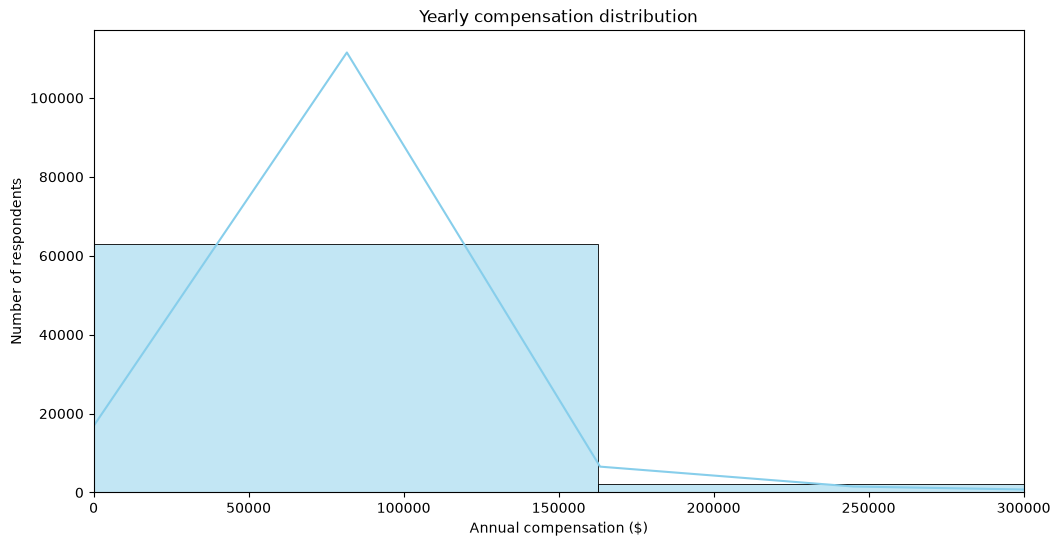

In [4]:
## Write your code here
middle_salary = df['ConvertedCompYearly'].median()
df['ConvertedCompYearly'] = df['ConvertedCompYearly'].fillna(middle_salary)

plt.figure(figsize=(12, 6))
sns.histplot(df['ConvertedCompYearly'], bins=100, color='skyblue', kde=True)
plt.xlim(0, 300000)
plt.title('Yearly compensation distribution')
plt.xlabel('Annual compensation ($)')
plt.ylabel('Number of respondents')
plt.show()

### Step 4: Calculate Median Compensation for Full-Time Employees


**Task**: Filter the data to calculate the median compensation for respondents whose employment status is `Employed, full-time.`


In [5]:
## Write your code here
full_time_workers = df[df['Employment'] == 'Employed, full-time']
median_value = full_time_workers['ConvertedCompYearly'].median()
print(f"Median of salary for full-time employees is: ${median_value:,.2f}")

Median of salary for full-time employees is: $65,000.00

**Saved result:** $65,000. The median represents the middle salary when the values are ordered. It is often more useful than the mean for salary data because a small number of very high salaries can pull an average upward.

This result should be interpreted carefully because missing salary values were filled with the overall median earlier. The filter also excludes respondents whose employment answer contains multiple statuses.

### Step 5: Analyzing Compensation Range and Distribution by Country


Explore the range of compensation in the ConvertedCompYearly column by analyzing differences across countries. Use box plots to compare the compensation distributions for each country to identify variations and anomalies within each region, providing insights into global compensation trends.



/tmp/ipykernel_3610/2064252986.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=filtered_countries, x='Country', y='ConvertedCompYearly', palette='Pastel1')

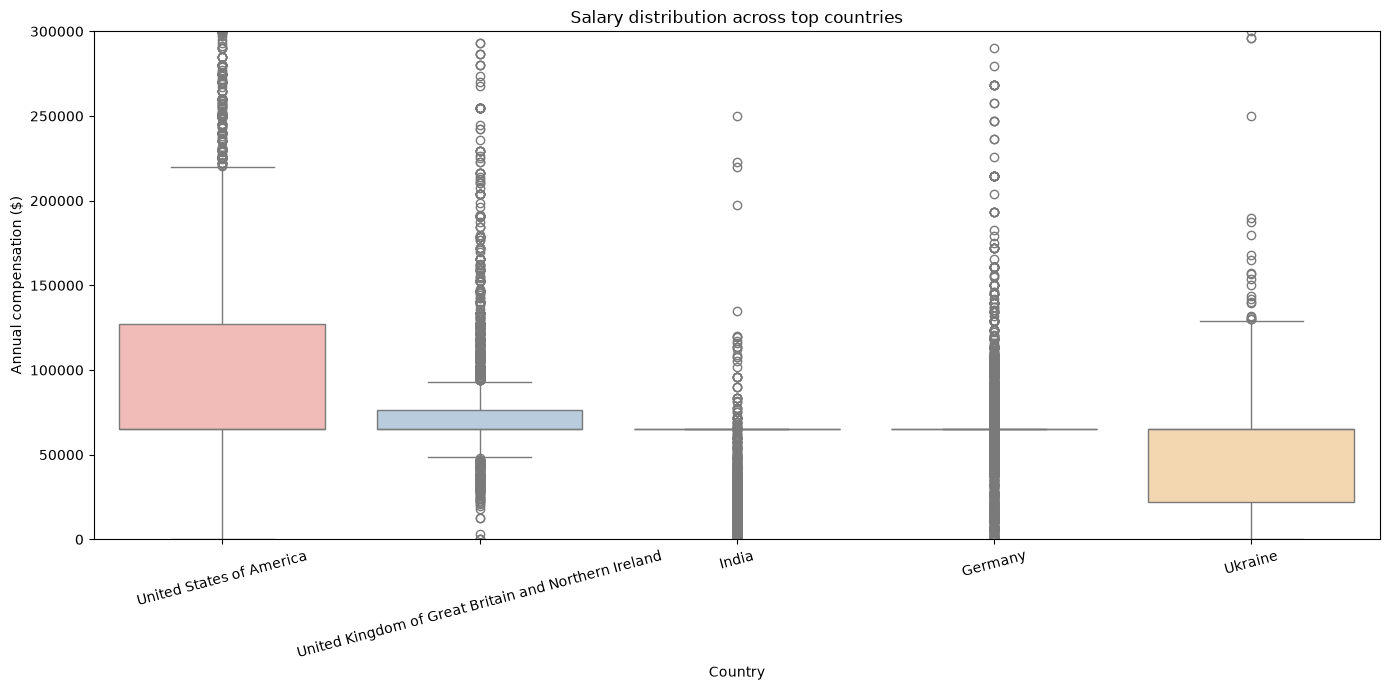

In [7]:
## Write your code here
top_countries = df['Country'].value_counts().nlargest(5).index
filtered_countries = df[df['Country'].isin(top_countries)]

plt.figure(figsize=(14, 7))
sns.boxplot(data=filtered_countries, x='Country', y='ConvertedCompYearly', palette='Pastel1')
plt.ylim(0, 300000)
plt.title('Salary distribution across top countries')
plt.ylabel('Annual compensation ($)')
plt.xlabel('Country')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

A box plot shows the middle portion of the distribution, the median, and points that lie farther from the main group. This is useful for comparing both typical compensation and variation within countries.

**How to interpret the chart:** These are unadjusted annual compensation figures, not cost-of-living-adjusted salaries. The vertical axis stops at $300,000, so some higher values are outside the visible range. Different response counts across countries can also affect the comparison.

### Step 6: Removing Outliers from the Dataset

**Task**: Create a new DataFrame by removing outliers from the `ConvertedCompYearly` column to get a refined dataset for correlation analysis.


In [8]:
## Write your code here
Q1 = df['ConvertedCompYearly'].quantile(0.25)
Q3 = df['ConvertedCompYearly'].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
df_clean = df[(df['ConvertedCompYearly'] >= lower_limit) & (df['ConvertedCompYearly'] <= upper_limit)].reset_index(drop=True)

print("Original dataset row count:", df.shape[0])
print("Refined dataset row count (outliers removed):", df_clean.shape[0])

Original dataset row count: 65437
Refined dataset row count (outliers removed): 42039

**Saved result:** The dataset decreases from 65,437 to 42,039 rows, meaning 23,398 rows are excluded by this rule.

**Important limitation:** Missing salaries were replaced with the median before calculating the IQR. In this dataset, that creates a large concentration at $65,000 and can make the IQR zero, so the filtering may retain only that imputed salary value. The smaller dataset should therefore not be treated as a reliable set of salaries with outliers removed. This also affects the correlation results that follow.

### Step 7: Finding Correlations Between Key Variables

**Task**: Calculate correlations between `ConvertedCompYearly`, `WorkExp`, and `JobSatPoints_1`. Visualize these correlations with a heatmap.


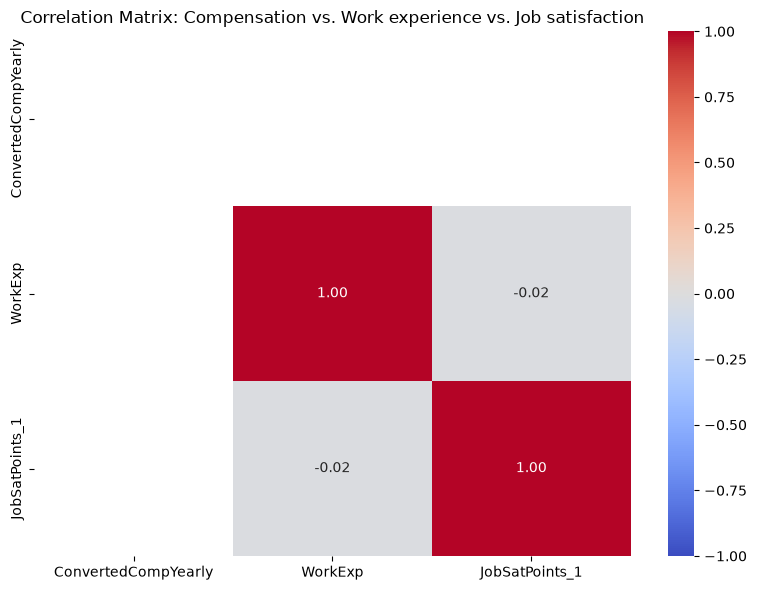

In [9]:
## Write your code here
df_clean['WorkExp'] = pd.to_numeric(df_clean['WorkExp'], errors='coerce').fillna(0)
targ_columns = ['ConvertedCompYearly', 'WorkExp', 'JobSatPoints_1']
corr_table = df_clean[targ_columns].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_table, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation Matrix: Compensation vs. Work experience vs. Job satisfaction')
plt.tight_layout()
plt.show()

Values near +1 indicate a strong positive linear relationship, values near -1 indicate a strong negative relationship, and values near 0 indicate little or no linear relationship.

### Step 8: Scatter Plot for Correlations

**Task**: Create scatter plots to examine specific correlations between `ConvertedCompYearly` and `WorkExp`, as well as between `ConvertedCompYearly` and `JobSatPoints_1`.


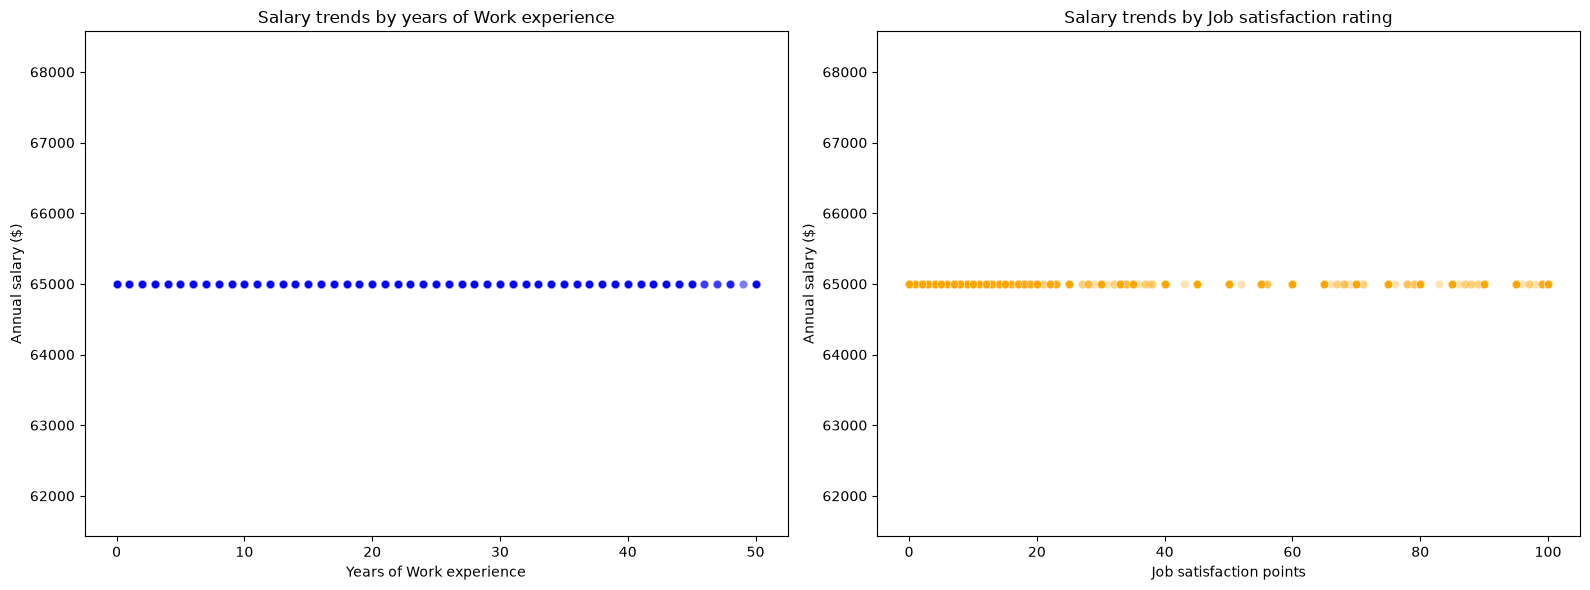

In [13]:
## Write your code here
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(data=df_clean, x='WorkExp', y='ConvertedCompYearly', alpha=0.3, color='blue', ax=axes[0])
axes[0].set_title('Salary trends by years of Work experience')
axes[0].set_ylabel('Annual salary ($)')
axes[0].set_xlabel('Years of Work experience')

sns.scatterplot(data=df_clean, x='JobSatPoints_1', y='ConvertedCompYearly', alpha=0.3, color='orange', ax=axes[1])
axes[1].set_title('Salary trends by Job satisfaction rating')
axes[1].set_ylabel('Annual salary ($)')
axes[1].set_xlabel('Job satisfaction points')
plt.tight_layout()
plt.show()

These charts complement the correlation matrix because they show the individual observations rather than reducing each relationship to a single number.

**What to watch for:** The previous IQR filter may have left a dataset dominated by the same salary value. If the points form a horizontal line, that reflects the data preparation rather than proving that experience or satisfaction has no relationship with pay. Correlation alone cannot establish cause and effect.

### Key Findings
- The saved median compensation for respondents classified as full-time employees is $65,000, although the earlier imputation influences that figure.
- The IQR filter reduces the dataset from 65,437 to 42,039 rows. Because median imputation can collapse the salary IQR to zero, this filtering result requires particular caution.
- Country-level box plots provide a way to compare salary distributions, but the figures are not adjusted for differences in living costs or survey composition.
- Correlation heatmaps and scatter plots are useful tools for investigating relationships, but the current filtered data is not a sound basis for conclusions about how salary relates to experience or satisfaction.

### Limitations and Next Steps
The main limitation is the order of preprocessing: missing compensation values are filled before outlier detection. A stronger follow-up analysis would keep missing salaries separate, calculate the IQR using observed compensation values, and inspect the resulting salary distribution before calculating correlations. I would also preserve missing experience as missing rather than converting it to zero and consider differences between countries when comparing compensation.

### Skills Demonstrated
- Exploratory analysis: Reviewing compensation distributions and comparing groups.
- Statistical methods: Calculating medians, IQR-based thresholds, and Pearson correlations.
- Visualization: Building histograms, box plots, heatmaps, and scatter plots.
- Analytical judgment: Recognizing how missing-value treatment and outlier filtering can change the conclusions.

<h3>Summary</h3>


In this lab, you practiced essential skills in correlation analysis by:
- Examining the distribution of yearly compensation with histograms and box plots.
- Detecting and removing outliers from compensation data.
- Calculating correlations between key variables such as compensation, work experience, and job satisfaction.
- Visualizing relationships with scatter plots and heatmaps to gain insights into the associations between these features.

*Attribution: Original lab materials and code are from IBM Skills Network. Portfolio explanations and interpretations have been added. The saved outputs were preserved and the notebook was not rerun.*

## Authors:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


Copyright © IBM Corporation. All rights reserved.
